# AI Revenue Optimization & Conversion Intelligence System for Nattoguard

## Notebook 01: Data Understanding

This notebook focuses on understanding the main dataset used for the conversion prediction component of the project.

The dataset used is the Online Shoppers Purchasing Intention Dataset. It contains customer session-level behavior data and a target column named `Revenue`, which indicates whether a user session resulted in a purchase.

The goal of this notebook is to inspect the dataset structure, check data quality, understand the target variable, and prepare the dataset for later exploratory data analysis and machine learning modeling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
DATA_PATH = "../data/raw/online_shoppers_intention.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [6]:
# Display all column names
df.columns.tolist()

['Administrative',
 'Administrative_Duration',
 'Informational',
 'Informational_Duration',
 'ProductRelated',
 'ProductRelated_Duration',
 'BounceRates',
 'ExitRates',
 'PageValues',
 'SpecialDay',
 'Month',
 'OperatingSystems',
 'Browser',
 'Region',
 'TrafficType',
 'VisitorType',
 'Weekend',
 'Revenue']

### Dataset Columns

The dataset contains customer session-level features such as page visits, page duration, bounce rate, exit rate, traffic type, visitor type, and the target variable `Revenue`.

The `Revenue` column is the target variable for this project. It indicates whether a user session resulted in a purchase.

In [7]:
# Check column data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [8]:
# Check missing values
missing_values = df.isnull().sum().sort_values(ascending=False)

missing_values

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [9]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


### Missing Value Check

The dataset does not contain missing values. This is useful because it reduces preprocessing complexity and allows the project to focus more on customer behavior analysis, model training, and business interpretation.

In [10]:
# Check duplicate records
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 125


In [11]:
# Remove duplicate rows
df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

Original dataset shape: (12330, 18)
Cleaned dataset shape: (12205, 18)


### Duplicate Row Handling

Duplicate records were checked to avoid repeated customer sessions affecting the machine learning model. Duplicate rows were removed and the cleaned dataset will be used for the next stages of the project.

In [12]:
# Check target variable distribution
df_clean["Revenue"].value_counts()

Revenue
False    10297
True      1908
Name: count, dtype: int64

In [13]:
# Target distribution percentage
target_distribution = df_clean["Revenue"].value_counts(normalize=True) * 100

target_distribution

Revenue
False    84.367063
True     15.632937
Name: proportion, dtype: float64

### Target Variable: Revenue

The target variable is `Revenue`.

- `True` means the customer session resulted in a purchase.
- `False` means the session did not result in a purchase.

This makes the project a binary classification problem, where the goal is to predict whether a customer session is likely to generate revenue.

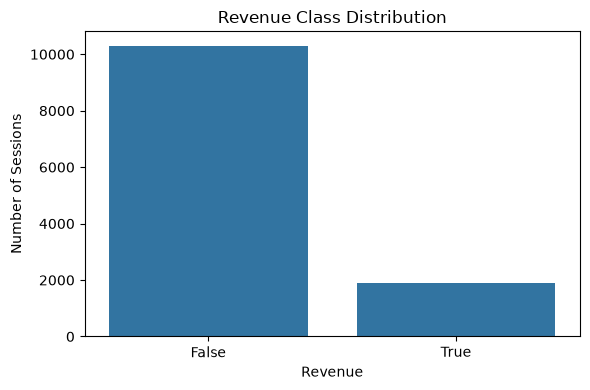

In [14]:
# Visualize revenue distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x="Revenue")
plt.title("Revenue Class Distribution")
plt.xlabel("Revenue")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

In [16]:
# Identify numerical and categorical columns
numeric_cols = df_clean.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df_clean.select_dtypes(include=["object", "bool"]).columns.tolist()

print("Numerical columns:")
print(numeric_cols)

print("\nCategorical / Boolean columns:")
print(categorical_cols)

Numerical columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Categorical / Boolean columns:
['Month', 'VisitorType', 'Weekend', 'Revenue']


C:\Users\misha\AppData\Local\Temp\ipykernel_37512\966942118.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(include=["object", "bool"]).columns.tolist()


### Feature Types

The dataset contains both numerical and categorical features.

Numerical features will be used directly or scaled depending on the model. Categorical features such as `Month`, `VisitorType`, `Weekend`, and `Revenue` will require encoding before machine learning model training.

In [17]:
# Statistical summary of numerical features
df_clean.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,2.124211,2.357804,3.153298,4.073904
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,0.906823,1.710114,2.402340,4.016654
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [18]:
df_clean.to_csv("../data/processed/online_shoppers_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.
